<a href="https://colab.research.google.com/github/damzy-ship/Api-project/blob/main/Download_and_Analyze_Food_Vision_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# --- IMPORTANT: Environment Setup for TensorFlow/Keras Compatibility ---
# This section helps resolve potential issues by ensuring a consistent
# TensorFlow and Keras version. After running this part, you MUST restart your Colab runtime.
# try:
#     print("Attempting to uninstall existing TensorFlow and Keras installations...")
#     get_ipython().system('pip uninstall -y tensorflow tensorflow-gpu keras')
#     print("Installing a specific compatible TensorFlow version (2.11.0) and tensorflow-hub...")
#     # Using a version known to have good compatibility with TF Hub and Keras 2.x behavior
#     get_ipython().system('pip install tensorflow==2.15 tensorflow-hub==0.16.1')
#     print("TensorFlow and TensorFlow Hub installation/reinstallation complete.")
#     print("--------------------------------------------------------------------")
#     print("IMPORTANT: Please RESTART YOUR RUNTIME NOW (Runtime -> Restart runtime...)")
#     print("           before executing any other cells to apply the changes.")
#     print("--------------------------------------------------------------------")
# except Exception as e:
#     print(f"Could not uninstall/install TensorFlow/Keras via pip: {e}")
#     print("Please ensure you are running this in a Google Colab environment or have pip installed.")
#     print("If the ValueError persists after restarting, it might be an inherent incompatibility")
#     print("between tensorflow-hub and the current Colab environment's Keras 3 default.")
# --- End of Environment Setup ---


Attempting to uninstall existing TensorFlow and Keras installations...
Found existing installation: tensorflow 2.18.0
Uninstalling tensorflow-2.18.0:
  Successfully uninstalled tensorflow-2.18.0
Found existing installation: keras 3.8.0
Uninstalling keras-3.8.0:
  Successfully uninstalled keras-3.8.0
Installing a specific compatible TensorFlow version (2.11.0) and tensorflow-hub...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 4.0 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of tf-keras to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 475.3/475.3 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 43.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 23.9 MB/s eta 0:00:

TensorFlow and TensorFlow Hub installation/reinstallation complete.
--------------------------------------------------------------------
IMPORTANT: Please RESTART YOUR RUNTIME NOW (Runtime -> Restart runtime...)
           before executing any other cells to apply the changes.
--------------------------------------------------------------------


In [1]:
import os
import zipfile
import urllib.request
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image # For robust image loading
import tensorflow as tf # Import TensorFlow
import datetime # Import datetime for TensorBoard logs
import tensorflow_hub as hub # Import TensorFlow Hub

In [2]:
print(tf. __version__)

2.15.0


In [3]:

# 1. Define the URL and destination filename
zip_url = "https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_10_percent.zip"
zip_filename = "10_food_classes_10_percent.zip"
extract_dir = "10_food_classes_10_percent" # The name of the folder inside the zip

print(f"Downloading {zip_filename} from {zip_url}...")

# Use !wget for simplicity in Google Colab.
# Alternatively, for pure Python, you can use urllib.request:
try:
    # !wget is a shell command, prefixed with '!' in Colab
    # This downloads the file to the current working directory
    get_ipython().system(f'wget {zip_url} -O {zip_filename}')
    print(f"Successfully downloaded {zip_filename}")
except Exception as e:
    print(f"Error downloading with wget: {e}. Trying urllib.request...")
    try:
        urllib.request.urlretrieve(zip_url, zip_filename)
        print(f"Successfully downloaded {zip_filename} using urllib.request")
    except Exception as e_urllib:
        print(f"Error downloading with urllib.request: {e_urllib}")
        print("Please ensure you are running this in an environment with internet access.")
        exit() # Exit if download fails


# 2. Unzip the file
print(f"Unzipping {zip_filename}...")
try:
    with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
        zip_ref.extractall(".") # Extract all contents to the current directory
    print(f"Successfully unzipped {zip_filename}")
except zipfile.BadZipFile:
    print(f"Error: {zip_filename} is not a valid zip file. It might be corrupted or incomplete.")
    exit()
except Exception as e:
    print(f"Error unzipping file: {e}")
    exit()

--2025-06-04 20:42:34--  https://storage.googleapis.com/ztm_tf_course/food_vision/10_food_classes_10_percent.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 74.125.20.207, 108.177.98.207, 142.250.99.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|74.125.20.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 168546183 (161M) [application/zip]
Saving to: ‘10_food_classes_10_percent.zip’

10_food_classes_10_ 100%[===================>] 160.74M   235MB/s    in 0.7s    

2025-06-04 20:42:35 (235 MB/s) - ‘10_food_classes_10_percent.zip’ saved [168546183/168546183]

Successfully downloaded 10_food_classes_10_percent.zip
Unzipping 10_food_classes_10_percent.zip...
Successfully unzipped 10_food_classes_10_percent.zip


In [4]:
# 3. List the number of images and classes

# Define the path to the extracted dataset (assuming it unzips into a folder with the same name as the zip)
dataset_path = os.path.join(os.getcwd(), extract_dir)

if not os.path.exists(dataset_path):
    print(f"Error: Extracted directory '{dataset_path}' not found.")
    print("Please check the contents of the zip file to confirm the top-level folder name.")
    exit()

print(f"\nAnalyzing dataset in: {dataset_path}")

num_classes = 0
num_images = 0
class_names = []

# Walk through the directory structure to count classes and images
for dirpath, dirnames, filenames in os.walk(dataset_path):
    # Count classes: A class is typically a subdirectory within the main train/test folders
    # We want to count the immediate subdirectories of 'train' and 'test'
    if os.path.basename(dirpath) in ['train', 'test']:
        for class_name in dirnames:
            class_names.append(os.path.join(os.path.basename(dirpath), class_name))
            num_classes += 1 # Increment for each class directory found

    # Count images: Iterate through files and check for common image extensions
    for filename in filenames:
        if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.gif', '.bmp')):
            num_images += 1

# Since the prompt states there are 10 classes, and the zip contains 'train' and 'test' folders,
# each having 10 subdirectories (classes), the total number of unique classes is 10.
# The `num_classes` variable will count 20 (10 for train, 10 for test) if not handled carefully.
# Let's adjust to count unique class names from the 'train' directory for accuracy.

unique_classes = set()
train_path = os.path.join(dataset_path, 'train')
test_path = os.path.join(dataset_path, 'test')

if os.path.exists(train_path):
    for dirpath, dirnames, filenames in os.walk(train_path):
        for dirname in dirnames:
            unique_classes.add(dirname)

final_num_classes = len(unique_classes)

print(f"\n--- Dataset Summary ---")
print(f"Total number of images found: {num_images}")
print(f"Total number of unique classes: {final_num_classes}")
print(f"Class names (from 'train' directory): {list(unique_classes)}")

# Optional: You can also print the count of images per class
print("\nImages per class (example for 'train' directory):")
if os.path.exists(train_path):
    for class_folder in os.listdir(train_path):
        class_folder_path = os.path.join(train_path, class_folder)
        if os.path.isdir(class_folder_path):
            image_count_in_class = len([f for f in os.listdir(class_folder_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
            print(f"  - {class_folder}: {image_count_in_class} images")
else:
    print(f"  'train' directory not found at {train_path}")

# Added: Count images per class for 'test' directory
print("\nImages per class (example for 'test' directory):")
if os.path.exists(test_path):
    for class_folder in os.listdir(test_path):
        class_folder_path = os.path.join(test_path, class_folder)
        if os.path.isdir(class_folder_path):
            image_count_in_class = len([f for f in os.listdir(class_folder_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
            print(f"  - {class_folder}: {image_count_in_class} images")
else:
    print(f"  'test' directory not found at {test_path}")


Analyzing dataset in: /content/10_food_classes_10_percent

--- Dataset Summary ---
Total number of images found: 3250
Total number of unique classes: 10
Class names (from 'train' directory): ['ramen', 'pizza', 'ice_cream', 'fried_rice', 'chicken_wings', 'sushi', 'steak', 'grilled_salmon', 'chicken_curry', 'hamburger']

Images per class (example for 'train' directory):
  - hamburger: 75 images
  - chicken_curry: 75 images
  - ice_cream: 75 images
  - fried_rice: 75 images
  - grilled_salmon: 75 images
  - ramen: 75 images
  - chicken_wings: 75 images
  - steak: 75 images
  - pizza: 75 images
  - sushi: 75 images

Images per class (example for 'test' directory):
  - hamburger: 250 images
  - chicken_curry: 250 images
  - ice_cream: 250 images
  - fried_rice: 250 images
  - grilled_salmon: 250 images
  - ramen: 250 images
  - chicken_wings: 250 images
  - steak: 250 images
  - pizza: 250 images
  - sushi: 250 images



--- Visualizing 10 random images from the 'train' dataset ---


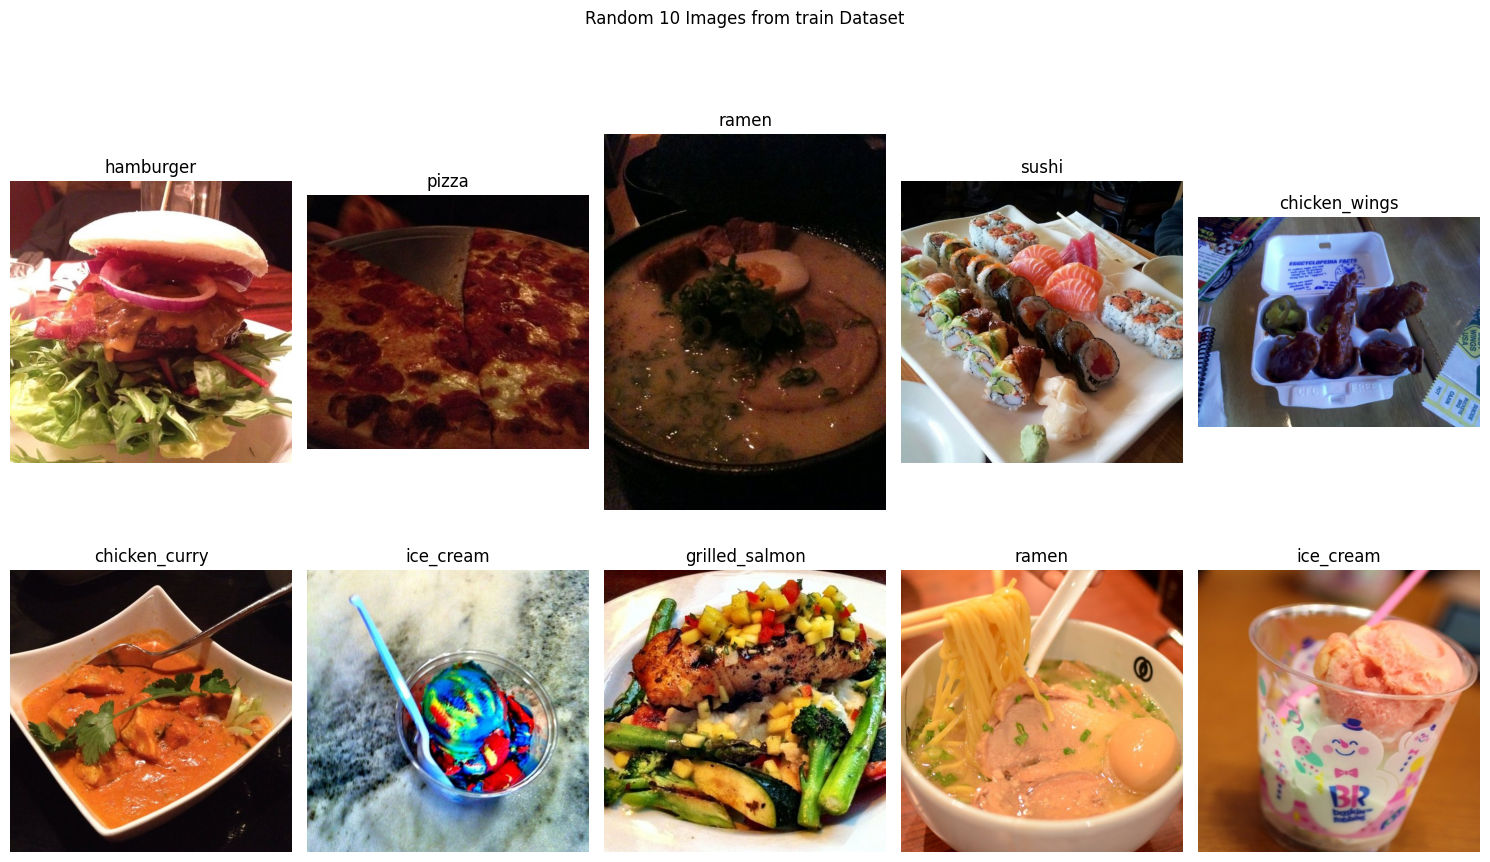

In [5]:
# 4. Function to visualize random images
def visualize_random_images(data_dir, num_images_to_show=10):
    """
    Visualizes a specified number of random images from the given directory.

    Args:
        data_dir (str): The path to the dataset directory (e.g., '10_food_classes_10_percent/train').
        num_images_to_show (int): The number of random images to display.
    """
    if not os.path.exists(data_dir):
        print(f"Error: Directory '{data_dir}' not found for visualization.")
        return

    all_image_paths = []
    for root, _, files in os.walk(data_dir):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg', '.gif', '.bmp')):
                all_image_paths.append(os.path.join(root, file))

    if not all_image_paths:
        print(f"No images found in '{data_dir}' to visualize.")
        return

    # Select random images
    random_image_paths = random.sample(all_image_paths, min(num_images_to_show, len(all_image_paths)))

    plt.figure(figsize=(15, 10))
    for i, img_path in enumerate(random_image_paths):
        plt.subplot(2, 5, i + 1) # Arrange in 2 rows, 5 columns
        try:
            img = Image.open(img_path) # Use PIL for robust image loading
            plt.imshow(img)
            # Extract class name from the path (e.g., 'train/pizza/image.jpg' -> 'pizza')
            class_name = os.path.basename(os.path.dirname(img_path))
            plt.title(class_name)
            plt.axis('off')
        except Exception as e:
            print(f"Could not load image {img_path}: {e}")
            plt.title("Error loading image")
            plt.axis('off')

    plt.suptitle(f"Random {min(num_images_to_show, len(all_image_paths))} Images from {os.path.basename(data_dir)} Dataset")
    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent title overlap
    plt.show()

# Example usage of the visualization function:
print("\n--- Visualizing 10 random images from the 'train' dataset ---")
visualize_random_images(train_path, num_images_to_show=10)

In [6]:
# 5. Preprocess data using ImageDataGenerator
print("\n--- Preprocessing data with ImageDataGenerator ---")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Create ImageDataGenerator for training data (rescaling only)
train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

# Create ImageDataGenerator for test data (rescaling only)
test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

print("\nProcessing training data:")
train_data = train_datagen.flow_from_directory(
    directory=train_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical' # Use 'categorical' for one-hot encoded labels
)

print("\nProcessing test data:")
test_data = test_datagen.flow_from_directory(
    directory=test_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

print("\n--- Preprocessing Results ---")
print(f"Train data batches: {train_data}")
print(f"  - Number of images: {train_data.samples}")
print(f"  - Number of classes: {train_data.num_classes}")
print(f"  - Class names: {train_data.class_indices}") # Shows mapping of class names to indices

print(f"\nTest data batches: {test_data}")
print(f"  - Number of images: {test_data.samples}")
print(f"  - Number of classes: {test_data.num_classes}")
print(f"  - Class names: {test_data.class_indices}") # Shows mapping of class names to indices


--- Preprocessing data with ImageDataGenerator ---

Processing training data:
Found 750 images belonging to 10 classes.

Processing test data:
Found 2500 images belonging to 10 classes.

--- Preprocessing Results ---
Train data batches: <keras.src.preprocessing.image.DirectoryIterator object at 0x7f26585c1dd0>
  - Number of images: 750
  - Number of classes: 10
  - Class names: {'chicken_curry': 0, 'chicken_wings': 1, 'fried_rice': 2, 'grilled_salmon': 3, 'hamburger': 4, 'ice_cream': 5, 'pizza': 6, 'ramen': 7, 'steak': 8, 'sushi': 9}

Test data batches: <keras.src.preprocessing.image.DirectoryIterator object at 0x7f265b8bf550>
  - Number of images: 2500
  - Number of classes: 10
  - Class names: {'chicken_curry': 0, 'chicken_wings': 1, 'fried_rice': 2, 'grilled_salmon': 3, 'hamburger': 4, 'ice_cream': 5, 'pizza': 6, 'ramen': 7, 'steak': 8, 'sushi': 9}


In [7]:
# 6. TensorBoard Callback Function
def create_tensorboard_callback(dir_name="tensorboard_logs", experiment_name="food_vision_model"):
    """
    Creates a TensorBoard callback to log model training history.

    Args:
        dir_name (str): The base directory where TensorBoard logs will be stored.
        experiment_name (str): A name for the current experiment, used to create a unique subdirectory.

    Returns:
        tf.keras.callbacks.TensorBoard: A configured TensorBoard callback.
    """
    log_dir = os.path.join(dir_name, experiment_name, datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
    print(f"Saving TensorBoard log files to: {log_dir}")
    tensorboard_callback = tf.keras.callbacks.TensorBoard(
        log_dir=log_dir
    )
    return tensorboard_callback

In [8]:
# 7. Function to create a model from TensorFlow Hub
def create_model_from_tf_hub(model_url, num_classes):
    """
    Creates a Keras model from a pre-trained TensorFlow Hub module.

    The model will have a feature extractor from TensorFlow Hub and a new
    output layer for the specified number of classes.

    Args:
        model_url (str): The URL of the TensorFlow Hub module (e.g., a feature vector).
        num_classes (int): The number of output classes for the new classification head.

    Returns:
        tf.keras.Model: A compiled Keras model ready for fine-tuning or training.
    """
    # Download the pre-trained model and save it as a Keras Layer
    feature_extractor_layer = hub.KerasLayer(
        model_url,
        trainable=False, # Freeze the already learned patterns
        name="feature_extraction_layer",
        input_shape=IMG_SIZE + (3,) # Use the global IMG_SIZE and add 3 for color channels
    )

    # Create our own model
    model = tf.keras.Sequential([
        feature_extractor_layer,
        tf.keras.layers.Dense(num_classes, activation='softmax', name='output_layer')
    ], name="food_vision_transfer_learning_model")

    return model

# Example usage (you would typically call this to create your model):
# Example Kaggle Model URLs for TensorFlow Hub feature vectors:
# EfficientNetB0:
efficientnet_b0_url = "https://www.kaggle.com/models/tensorflow/efficientnet/tensorflow2/b0-feature-vector/1"
# ResNet50V2:
resnet50_v2_url = "https://www.kaggle.com/models/tensorflow/resnet-50/TensorFlow2/feature-vector/1" # Corrected ResNet50V2 URL

num_classes = 10 # Using the detected number of unique classes
# model_efficientnet = create_model_from_tf_hub(efficientnet_b0_url, num_classes)
# model_efficientnet.summary()

# This line was causing the error due to a potential Keras/TensorFlow version mismatch.
# Ensure you restart the runtime after running the environment setup.
model_resnet = create_model_from_tf_hub(resnet50_v2_url, num_classes)
model_resnet.summary()

Model: "food_vision_transfer_learning_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 feature_extraction_layer (  (None, 2048)              23561152  
 KerasLayer)                                                     
                                                                 
 output_layer (Dense)        (None, 10)                20490     
                                                                 
Total params: 23581642 (89.96 MB)
Trainable params: 20490 (80.04 KB)
Non-trainable params: 23561152 (89.88 MB)
_________________________________________________________________


In [9]:
# 8. Compile and Fit the model_resnet
print("\n--- Compiling and Fitting the ResNet50V2 Model ---")

# Compile the model
model_resnet.compile(
    optimizer=tf.keras.optimizers.Adam(), # Adam optimizer is a good default
    loss=tf.keras.losses.CategoricalCrossentropy(), # Use CategoricalCrossentropy for one-hot encoded labels
    metrics=['accuracy']
)

# Create a TensorBoard callback for this model
resnet_tensorboard_callback = create_tensorboard_callback(experiment_name="resnet50_v2_transfer_learning")

# Fit the model
# You might want to adjust the number of epochs based on your needs and computational resources.
# For demonstration, we'll use a small number of epochs.
history_resnet = model_resnet.fit(
    train_data,
    epochs=5, # You can increase this for better training
    steps_per_epoch=len(train_data),
    validation_data=test_data,
    validation_steps=len(test_data),
    callbacks=[resnet_tensorboard_callback]
)

print("\n--- Model Fitting Complete ---")
print("History of ResNet50V2 model training:")
print(history_resnet.history)


--- Compiling and Fitting the ResNet50V2 Model ---
Saving TensorBoard log files to: tensorboard_logs/resnet50_v2_transfer_learning/20250604-204540
Epoch 1/5
24/24 [==============================] - 509s 22s/step - loss: 2.0172 - accuracy: 0.3360 - val_loss: 1.1691 - val_accuracy: 0.6256
Epoch 2/5
24/24 [==============================] - 511s 22s/step - loss: 0.8658 - accuracy: 0.7400 - val_loss: 0.7524 - val_accuracy: 0.7716
Epoch 3/5
24/24 [==============================] - 524s 23s/step - loss: 0.5622 - accuracy: 0.8440 - val_loss: 0.6564 - val_accuracy: 0.7960
Epoch 4/5
24/24 [==============================] - 506s 22s/step - loss: 0.4424 - accuracy: 0.8813 - val_loss: 0.6170 - val_accuracy: 0.8080
Epoch 5/5
24/24 [==============================] - 507s 22s/step - loss: 0.3450 - accuracy: 0.9280 - val_loss: 0.5668 - val_accuracy: 0.8276

--- Model Fitting Complete ---
History of ResNet50V2 model training:
{'loss': [2.017240285873413, 0.8658133745193481, 0.5621705055236816, 0.442376


--- Plotting Model History Curves ---


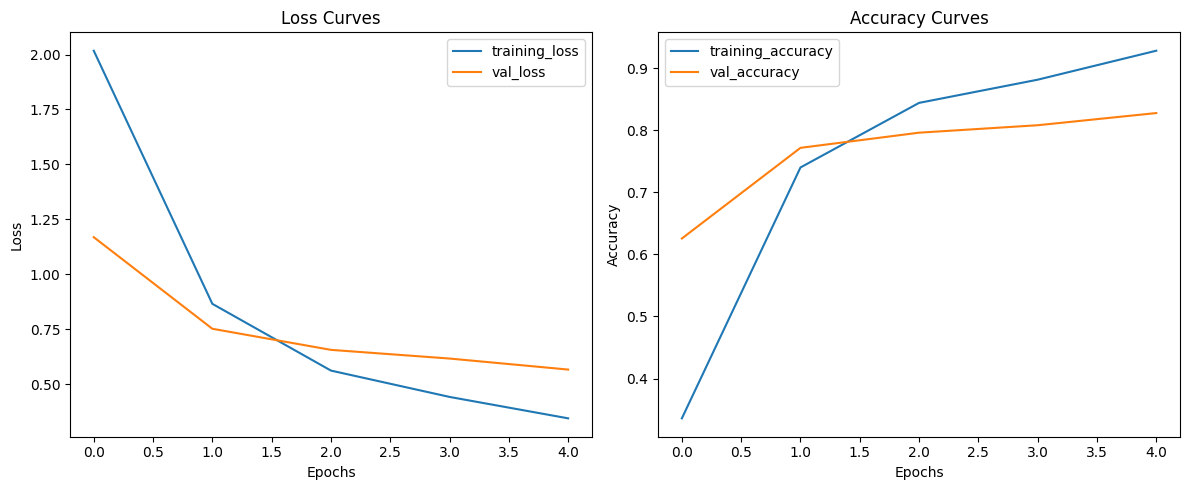

In [10]:
# 9. Custom function for viewing model's history loss and accuracy curves
def plot_loss_curves(history):
    """
    Returns separate loss and accuracy curves from a trained Keras model's history.

    Args:
        history: A tf.keras.callbacks.History object.
    """
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    accuracy = history.history['accuracy']
    val_accuracy = history.history['val_accuracy']

    epochs = range(len(history.history['loss']))

    # Plot loss
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label='training_loss')
    plt.plot(epochs, val_loss, label='val_loss')
    plt.title('Loss Curves')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # Plot accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label='training_accuracy')
    plt.plot(epochs, val_accuracy, label='val_accuracy')
    plt.title('Accuracy Curves')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Example usage of the plotting function after model fitting:
print("\n--- Plotting Model History Curves ---")
plot_loss_curves(history_resnet)



--- Predicting on a sample image (test_image09.jpg) ---
1/1 [==============================] - 0s 151ms/step


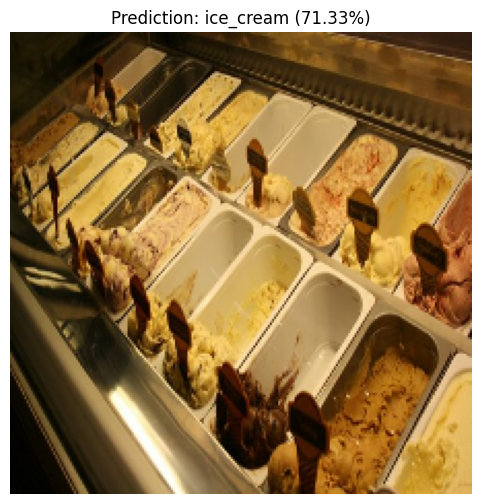

In [21]:
import numpy as np

# 10. Custom function to predict and plot image class
def predict_and_plot_image(filepath, model, class_names, img_size=(224, 224)):
    """
    Loads an image, makes a prediction using a trained model, and plots the image
    with its predicted class name.

    Args:
        filepath (str): Path to the image file.
        model (tf.keras.Model): Trained TensorFlow Keras model.
        class_names (list): List of class names in the order corresponding to model's output.
        img_size (tuple): Target size for image resizing (width, height).
    """
    # Load and preprocess the image
    try:
        img = tf.io.read_file(filepath)
        img = tf.image.decode_image(img, channels=3) # Ensure 3 channels for color images
        img = tf.image.resize(img, size=img_size)
        img = img / 255. # Rescale to [0, 1] as done in ImageDataGenerator
        img = tf.expand_dims(img, axis=0) # Add batch dimension (e.g., (1, 224, 224, 3))
    except Exception as e:
        print(f"Error loading or preprocessing image {filepath}: {e}")
        return

    # Make a prediction
    prediction_probs = model.predict(img)
    predicted_class_index = np.argmax(prediction_probs)
    predicted_class_name = class_names[predicted_class_index]
    confidence = np.max(prediction_probs) * 100

    # Plot the image and prediction
    plt.figure(figsize=(6, 6))
    plt.imshow(img[0]) # Remove batch dimension for plotting
    plt.title(f"Prediction: {predicted_class_name} ({confidence:.2f}%)")
    plt.axis('off')
    plt.show()

# Example usage of the prediction function:
# To use this, you would need to upload an image to your Colab environment
# For example, if you upload 'my_test_image.jpeg' to the root directory:
#
# First, get the list of class names from your training data generator
# This ensures the order of class names matches the model's output
class_names_list = sorted(train_data.class_indices.keys())

# Example: Create a dummy image file for demonstration if no actual image is uploaded
# In a real scenario, you would replace this with an actual uploaded image path.
dummy_image_path = "test_image09.jpg"
if not os.path.exists(dummy_image_path):
    try:
        # Create a simple blank image as a placeholder
        dummy_img = Image.new('RGB', IMG_SIZE, color = 'red')
        dummy_img.save(dummy_image_path)
        print(f"Created a dummy image at {dummy_image_path} for demonstration.")
    except Exception as e:
        print(f"Could not create dummy image: {e}. Please upload an image manually to test this function.")
        dummy_image_path = None # Set to None if creation fails

if dummy_image_path and os.path.exists(dummy_image_path):
    print(f"\n--- Predicting on a sample image ({dummy_image_path}) ---")
    predict_and_plot_image(dummy_image_path, model_resnet, class_names_list)
else:
    print("\nSkipping prediction example as no image (or dummy image) is available.")
    print("To test the prediction function, please upload an image to your Colab environment")
    print("and replace 'dummy_test_image.jpg' with the actual path to your uploaded image.")
